Language: **English (default)** | [Polski](examples.ipynb)

# Lecture 04. Optimization geometry and MLP training

This notebook supplements [`lecture.en.md`](lecture.en.md) with two experiments.
The first compares SGD, momentum, and Adam on a two-dimensional,
ill-conditioned quadratic function using contours, trajectories, and
stability boundaries. The second trains a small MLP on synthetic data with
a shared and a separately tuned learning rate.

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 1. Optimization geometry

The function $f(x,y) = \tfrac12(a x^2 + b y^2)$ with $a=25$ and $b=1$ is
steep in the $x$ direction and flat in the $y$ direction. Its minimum is
at $(0,0)$, and the starting point is $(1,1)$.

In [2]:
A, B = 25.0, 1.0
START = [1.0, 1.0]


def f(xy):
    return 0.5 * (A * xy[0] ** 2 + B * xy[1] ** 2)


def run(opt_name, lr, steps, momentum=0.9, betas=(0.9, 0.999)):
    theta = torch.tensor(START, requires_grad=True)
    if opt_name == "sgd":
        opt = torch.optim.SGD([theta], lr=lr)
    elif opt_name == "momentum":
        opt = torch.optim.SGD([theta], lr=lr, momentum=momentum)
    elif opt_name == "adam":
        opt = torch.optim.Adam([theta], lr=lr, betas=betas)
    traj = [theta.detach().clone().tolist()]
    losses = [f(theta).item()]
    for _ in range(steps):
        opt.zero_grad()
        loss = f(theta)
        loss.backward()
        opt.step()
        traj.append(theta.detach().clone().tolist())
        losses.append(f(theta).item())
    return traj, losses


def plot_contours(ax, xlim=(-1.3, 1.3), ylim=(-1.3, 1.3)):
    xs = torch.linspace(*xlim, 200)
    ys = torch.linspace(*ylim, 200)
    XX, YY = torch.meshgrid(xs, ys, indexing="xy")
    ZZ = 0.5 * (A * XX**2 + B * YY**2)
    ax.contour(XX, YY, ZZ, levels=20, cmap="Greys", alpha=0.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")


def plot_trajectory(ax, traj, label, **kwargs):
    xs = [p[0] for p in traj]
    ys = [p[1] for p in traj]
    ax.plot(xs, ys, marker="o", markersize=3, linewidth=1, label=label, **kwargs)

### SGD: the stability boundary

For $f=\tfrac12 a x^2$, plain gradient descent is stable when
$\eta < 2/a$. Here $a=25$, so the boundary is $\eta=0.08$.

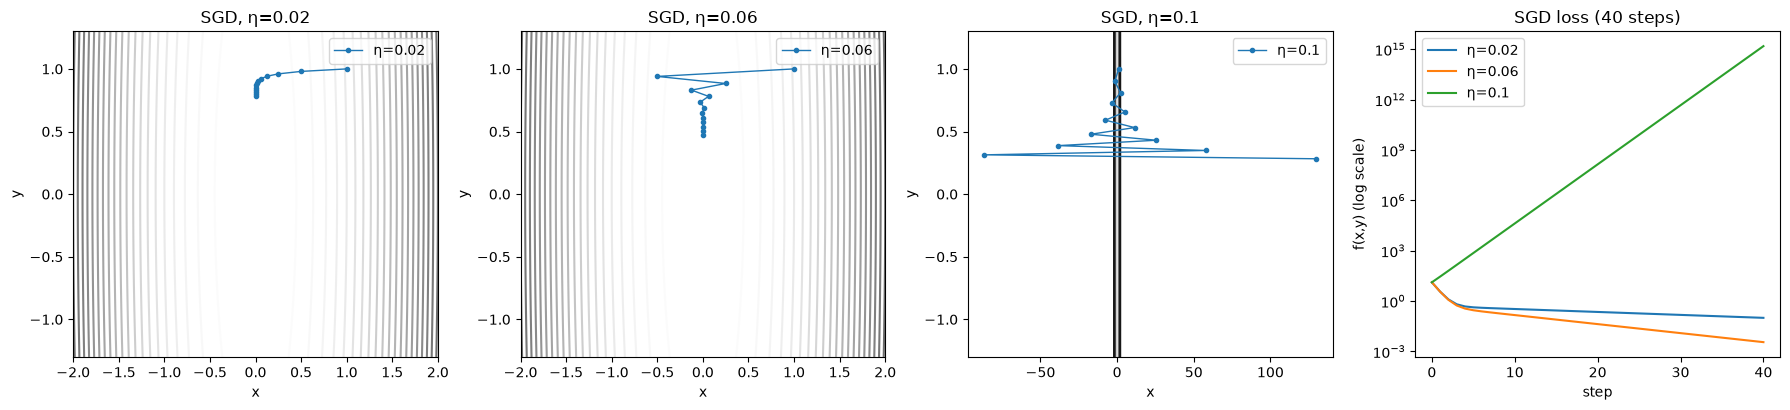

SGD eta=0.02: final loss=0.0993  sign changes of x=0  last x=0.000
SGD eta=0.06: final loss=0.0035  sign changes of x=40  last x=0.000
SGD eta=0.1: final loss=1528309217230848.0000  sign changes of x=40  last x=11057339.000


In [3]:
lrs_sgd = [0.02, 0.06, 0.1]
results_sgd = {lr: run("sgd", lr, steps=40) for lr in lrs_sgd}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, lr in zip(axes[:3], lrs_sgd):
    traj, _ = results_sgd[lr]
    traj_short = traj[:13]  # the qualitative behavior is already visible in the first few steps
    plot_contours(ax, xlim=(-2, 2), ylim=(-1.3, 1.3))
    plot_trajectory(ax, traj_short, f"η={lr}")
    ax.set_title(f"SGD, η={lr}")
    ax.legend()

for lr in lrs_sgd:
    _, losses = results_sgd[lr]
    axes[3].semilogy([v + 1e-12 for v in losses], label=f"η={lr}")
axes[3].set_xlabel("step")
axes[3].set_ylabel("f(x,y) (log scale)")
axes[3].set_title("SGD loss (40 steps)")
axes[3].legend()
plt.tight_layout()
plt.show()

for lr in lrs_sgd:
    traj, losses = results_sgd[lr]
    xs = [p[0] for p in traj]
    sign_changes = sum(1 for i in range(1, len(xs)) if xs[i] * xs[i - 1] < 0)
    print(
        f"SGD eta={lr}: final loss={losses[-1]:.4f}  "
        f"sign changes of x={sign_changes}  last x={xs[-1]:.3f}"
    )

### Momentum with the same $\eta$ and different $\beta$

At $\eta=0.06$, plain SGD oscillates but remains convergent.

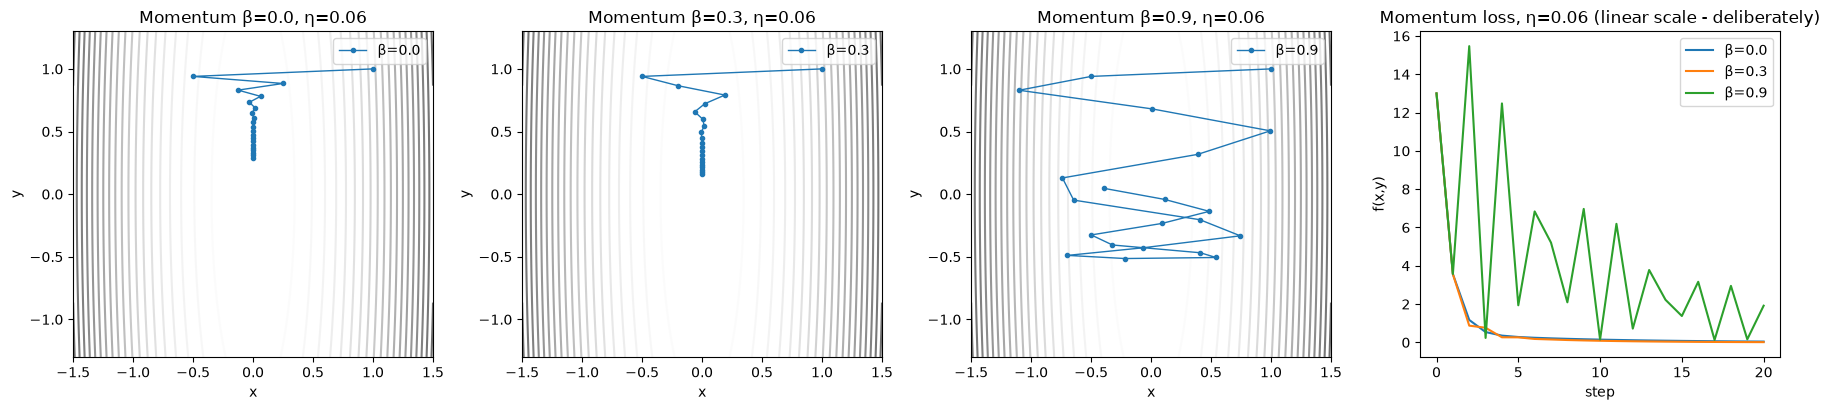

momentum beta=0.0: loss after 20 steps=0.0421  min=0.0421 max=13.0000
momentum beta=0.3: loss after 20 steps=0.0130  min=0.0130 max=13.0000
momentum beta=0.9: loss after 20 steps=1.9163  min=0.1290 max=15.4691


In [4]:
lr_shared = 0.06
betas_to_try = [0.0, 0.3, 0.9]
results_mom = {beta: run("momentum", lr_shared, steps=20, momentum=beta) for beta in betas_to_try}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, beta in zip(axes[:3], betas_to_try):
    traj, _ = results_mom[beta]
    plot_contours(ax, xlim=(-1.5, 1.5), ylim=(-1.3, 1.3))
    plot_trajectory(ax, traj, f"β={beta}")
    ax.set_title(f"Momentum β={beta}, η={lr_shared}")
    ax.legend()

for beta in betas_to_try:
    _, losses = results_mom[beta]
    axes[3].plot(losses, label=f"β={beta}")
axes[3].set_xlabel("step")
axes[3].set_ylabel("f(x,y)")
axes[3].set_title(f"Momentum loss, η={lr_shared} (linear scale - deliberately)")
axes[3].legend()
plt.tight_layout()
plt.show()

for beta in betas_to_try:
    traj, losses = results_mom[beta]
    print(
        f"momentum beta={beta}: loss after 20 steps={losses[-1]:.4f}  "
        f"min={min(losses):.4f} max={max(losses):.4f}"
    )

During the first 20 steps, $\beta=0.9$ at $\eta=0.06$ produces strong
oscillations and no consistent loss decrease. This horizon is too short to
establish instability. A longer run allows inspection of the update matrix's
spectral radius. The smaller $\eta$ is included as a faster option under a
finite step budget, not as a requirement for convergence.

In [5]:
_, losses_long = run("momentum", 0.06, steps=100, momentum=0.9)
_, losses_small_lr = run("momentum", 0.02, steps=40, momentum=0.9)


def momentum_spectral_radius(curvature, lr=0.06, momentum=0.9):
    update = torch.tensor(
        [[1 - lr * curvature, -lr * momentum], [curvature, momentum]],
        dtype=torch.float64,
    )
    return torch.linalg.eigvals(update).abs().max().item()


print(
    "momentum beta=0.9, eta=0.06: loss after 20/40/100 steps = "
    f"{losses_long[20]:.6f} / {losses_long[40]:.6f} / {losses_long[100]:.6f}"
)
for curvature in (A, B):
    radius = momentum_spectral_radius(curvature)
    print(
        f"spectral radius for curvature a={curvature:g}: {radius:.6f} (< 1, asymptotically stable)"
    )
print(f"for comparison, eta=0.02: loss after 40 steps = {losses_small_lr[-1]:.6f}")

momentum beta=0.9, eta=0.06: loss after 20/40/100 steps = 1.916347 / 0.006574 / 0.000025
spectral radius for curvature a=25: 0.948683 (< 1, asymptotically stable)
spectral radius for curvature a=1: 0.948683 (< 1, asymptotically stable)
for comparison, eta=0.02: loss after 40 steps = 0.003000


### Adam and per-parameter scaling

The trajectories show the effect of the 25-fold curvature difference between
the $x$ and $y$ directions.

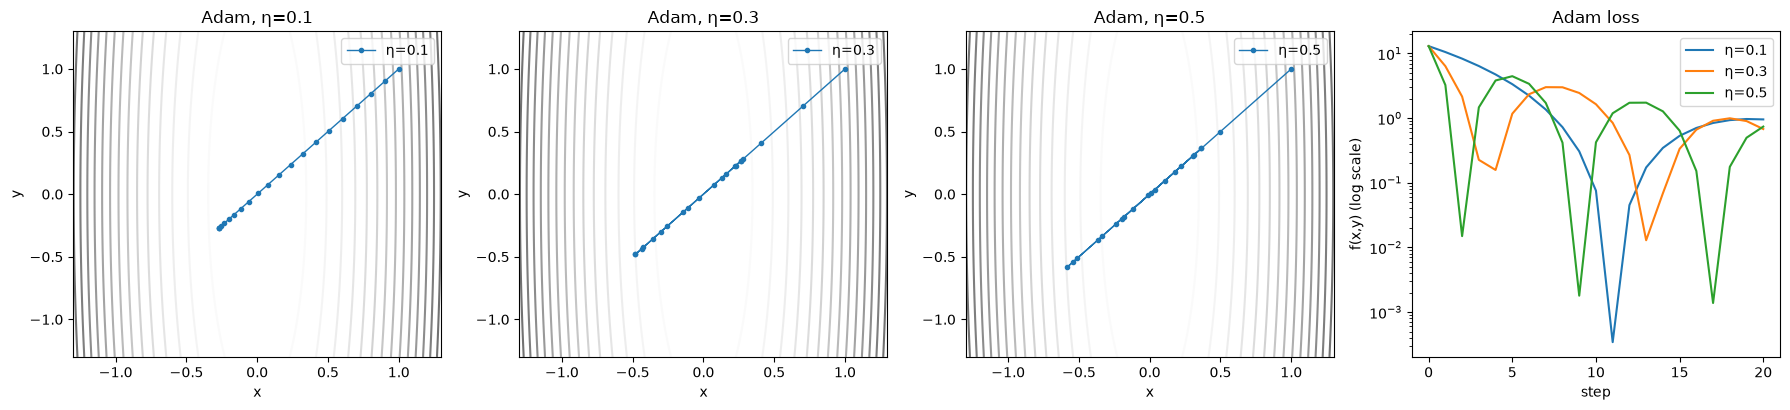

Adam eta=0.1: maximum |x-y| along the whole trajectory = 5.96e-08
(x and y are practically identical at every step, despite a/b=25 curvature difference)


In [6]:
lrs_adam = [0.1, 0.3, 0.5]
results_adam = {lr: run("adam", lr, steps=20) for lr in lrs_adam}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, lr in zip(axes[:3], lrs_adam):
    traj, _ = results_adam[lr]
    plot_contours(ax, xlim=(-1.3, 1.3), ylim=(-1.3, 1.3))
    plot_trajectory(ax, traj, f"η={lr}")
    ax.set_title(f"Adam, η={lr}")
    ax.legend()

for lr in lrs_adam:
    _, losses = results_adam[lr]
    axes[3].semilogy([v + 1e-12 for v in losses], label=f"η={lr}")
axes[3].set_xlabel("step")
axes[3].set_ylabel("f(x,y) (log scale)")
axes[3].set_title("Adam loss")
axes[3].legend()
plt.tight_layout()
plt.show()

traj01, _ = results_adam[0.1]
max_xy_diff = max(abs(p[0] - p[1]) for p in traj01)
print(f"Adam eta=0.1: maximum |x-y| along the whole trajectory = {max_xy_diff:.2e}")
print("(x and y are practically identical at every step, despite a/b=25 curvature difference)")

## 2. Training an MLP with shared and separately tuned learning rates

The dataset contains two interleaving half-moons and $N=2000$ examples. It
uses an 80/20 split and mini-batches of 64. An explicit function shuffles
indices with a fixed seed.

In [7]:
def make_moons(n_samples, noise, seed):
    g = torch.Generator().manual_seed(seed)
    n0 = n_samples // 2
    n1 = n_samples - n0
    theta0 = torch.pi * torch.rand(n0, generator=g)
    moon0 = torch.stack([torch.cos(theta0), torch.sin(theta0)], dim=1)
    theta1 = torch.pi * torch.rand(n1, generator=g)
    moon1 = torch.stack([1 - torch.cos(theta1), 1 - torch.sin(theta1) - 0.5], dim=1)
    X = torch.cat([moon0, moon1], dim=0)
    y = torch.cat([torch.zeros(n0), torch.ones(n1)])
    X = X + noise * torch.randn(X.shape[0], 2, generator=g)
    perm = torch.randperm(X.shape[0], generator=g)
    return X[perm], y[perm]


X, y = make_moons(n_samples=2000, noise=0.25, seed=0)
n = X.shape[0]
split_perm = torch.randperm(n, generator=torch.Generator().manual_seed(1))
n_val = int(0.2 * n)
val_idx, train_idx = split_perm[:n_val], split_perm[n_val:]
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
print(f"N_train={len(train_idx)}, N_val={len(val_idx)}")


def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 1))


def iterate_minibatches(X, y, batch_size, seed):
    """Explicit mini-batch construction: permute indices, slice into chunks."""
    g = torch.Generator().manual_seed(seed)
    n = X.shape[0]
    perm = torch.randperm(n, generator=g)
    for i in range(0, n, batch_size):
        idx = perm[i : i + batch_size]
        yield X[idx], y[idx]


def train_model(opt_name, lr, epochs, batch_size=64, model_seed=42, data_seed=123, momentum=0.9):
    model = make_model(model_seed)
    if opt_name == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=lr)
    elif opt_name == "momentum":
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    elif opt_name == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    train_losses, val_losses = [], []
    for epoch in range(epochs):
        for xb, yb in iterate_minibatches(X_train, y_train, batch_size, seed=data_seed + epoch):
            opt.zero_grad()
            logits = model(xb).squeeze(-1)
            loss = loss_fn(logits, yb)
            loss.backward()
            opt.step()
        with torch.no_grad():
            train_losses.append(loss_fn(model(X_train).squeeze(-1), y_train).item())
            val_losses.append(loss_fn(model(X_val).squeeze(-1), y_val).item())
    return train_losses, val_losses

N_train=1600, N_val=400


### A controlled experiment with shared $\eta=0.01$

sgd        (eta=0.01)  train@30=0.3295  val@30=0.3739


momentum   (eta=0.01)  train@30=0.2541  val@30=0.3023


adam       (eta=0.01)  train@30=0.1302  val@30=0.1503


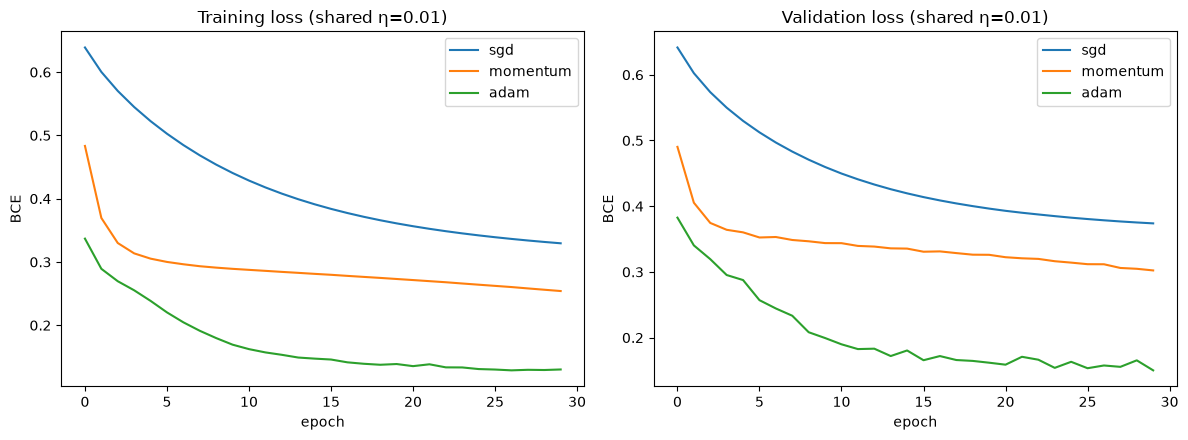

In [8]:
EPOCHS = 30
common_results = {}
for name in ["sgd", "momentum", "adam"]:
    tl, vl = train_model(name, lr=0.01, epochs=EPOCHS)
    common_results[name] = (tl, vl)
    print(f"{name:10s} (eta=0.01)  train@{EPOCHS}={tl[-1]:.4f}  val@{EPOCHS}={vl[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (tl, vl) in common_results.items():
    axes[0].plot(tl, label=name)
    axes[1].plot(vl, label=name)
axes[0].set_title("Training loss (shared η=0.01)")
axes[1].set_title("Validation loss (shared η=0.01)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("BCE")
    ax.legend()
plt.tight_layout()
plt.show()

### An experiment with a separately tuned $\eta$ for each algorithm

**This is a separate experiment.** Each optimizer receives its own tuned
value of $\eta$ instead of a shared value.

sgd        (eta=0.5)  train@30=0.1379  val@30=0.1717


momentum   (eta=0.1)  train@30=0.1262  val@30=0.1520


adam       (eta=0.01)  train@30=0.1302  val@30=0.1503


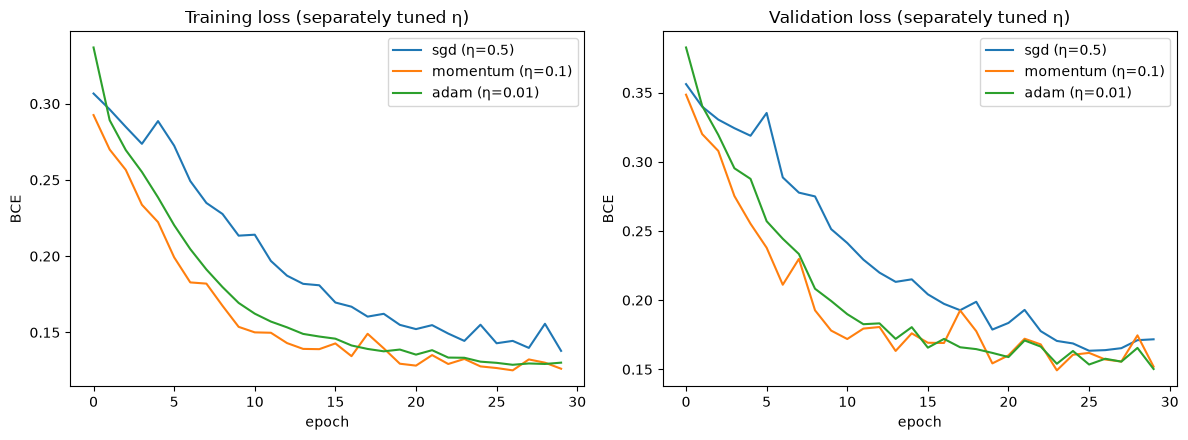

In [9]:
tuned_lrs = {"sgd": 0.5, "momentum": 0.1, "adam": 0.01}
tuned_results = {}
for name, lr in tuned_lrs.items():
    tl, vl = train_model(name, lr=lr, epochs=EPOCHS)
    tuned_results[name] = (tl, vl)
    print(f"{name:10s} (eta={lr})  train@{EPOCHS}={tl[-1]:.4f}  val@{EPOCHS}={vl[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (tl, vl) in tuned_results.items():
    axes[0].plot(tl, label=f"{name} (η={tuned_lrs[name]})")
    axes[1].plot(vl, label=f"{name} (η={tuned_lrs[name]})")
axes[0].set_title("Training loss (separately tuned η)")
axes[1].set_title("Validation loss (separately tuned η)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("BCE")
    ax.legend()
plt.tight_layout()
plt.show()

### The effect of the learning rate on stability (SGD)

SGD eta=1.0: training loss after 15 epochs = 0.1456  (first 5: [0.291, 0.282, 0.269, 0.238, 0.285])
SGD eta=3.0: training loss after 15 epochs = 0.1380  (first 5: [0.246, 0.21, 0.169, 0.145, 0.167])
SGD eta=8.0: training loss after 15 epochs = 0.2750  (first 5: [0.297, 0.296, 0.322, 0.266, 0.705])


SGD eta=15.0: training loss after 15 epochs = 1.6623  (first 5: [0.48, 0.532, 0.466, 0.992, 0.611])


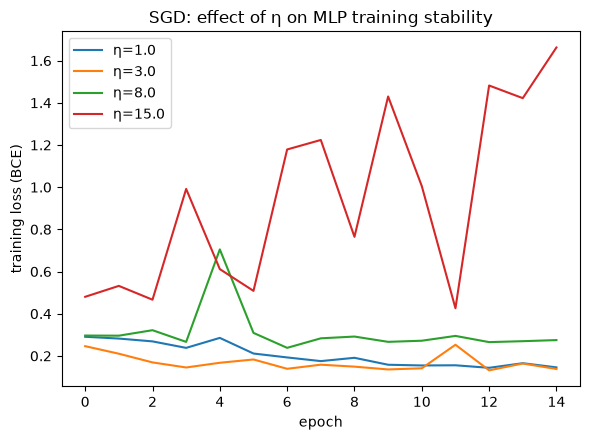

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for lr in [1.0, 3.0, 8.0, 15.0]:
    tl, _ = train_model("sgd", lr=lr, epochs=15)
    ax.plot(tl, label=f"η={lr}")
    first5 = [round(x, 3) for x in tl[:5]]
    print(f"SGD eta={lr}: training loss after 15 epochs = {tl[-1]:.4f}  (first 5: {first5})")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss (BCE)")
ax.set_title("SGD: effect of η on MLP training stability")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

- The SGD stability boundary for this function appears exactly where theory
  predicts, at $\eta=2/a$. Momentum changes the dynamics. It can oscillate strongly
  and be slow over a short horizon while remaining asymptotically stable.
  Stability and convergence speed are not the same thing.
- Adam normalizes the step separately for each parameter. For this function,
  the same $\eta$ gives identical behavior in the steep and flat directions.
- Comparing at a shared $\eta$ and comparing at a separately tuned $\eta$
  produced **different** conclusions. This follows from the effect described
  in the lecture. An advantage observed at one value of $\eta$
  is often an advantage in robustness to the choice of $\eta$, not in the
  quality of the mechanism itself.

Discussion questions and references are available in [`lecture.en.md`](lecture.en.md).